# K-means · Estabilidad respecto de la declinación propia

**Definición acordada:** estable es un pozo que sigue su tendencia de declinación sin picos o
caídas importantes sin explicar. Este cuaderno mide **desviaciones respecto de esa tendencia**
y conserva contexto operativo para su revisión. No puede demostrar automáticamente que un evento sea inexplicable.

El modelo, sus métricas y sus gráficos utilizan únicamente **petróleo y gas**.
El agua queda excluida de todo el modelado.

## 1. Diseño y decisiones metodológicas

1. Fijar un corte común y construir explícitamente sus 12 meses. Un mes ausente no se rellena con cero.
2. Exigir los 12 meses presentes, datos de producción válidos y edad coherente con el calendario.
3. Ajustar una **curva hiperbólica robusta propia** por pozo y fluido en esa ventana, usando la edad observada.
4. Medir magnitud, frecuencia y persistencia de sus desviaciones normalizadas.
5. Transformar y escalar las variables; ajustar K-means con grupos por area de yacimiento y fluidos.

La curva de declinación hiperbólica:
$$
q(\mathrm{edad}) =
\frac{q_{\mathrm{ref}}}
{\left[1+bD\left(\mathrm{edad}-\mathrm{edad}_{\mathrm{ref}}\right)\right]^{1/b}}
$$
donde `edad_ref` es la edad real en el primer mes de la ventana y `q_ref` su tasa ajustada. Cada pozo tiene sus propios
`q_ref`, `D` y `b`: un pozo de edad 80–91 meses no se alinea artificialmente con otro de edad 20–31.

Referencias: [curvas de declinación de EIA](https://www.eia.gov/analysis/drilling/curve_analysis/2020/)

Se restringe `D ≥ 0` y se permite el caso límite de tasa constante. La forma hiperbólica se utiliza
como **referencia descriptiva**, no como estimación de reservas ni prueba de un régimen físico.
Para agua, que puede tener una tendencia creciente, el supuesto de declinación necesita especial revisión.
Un aumento sostenido, una intervención o una mala curva también pueden generar residuos grandes.

La edad y el volumen absoluto no entran como variables directas de K-means.


In [69]:
# Importamos solo las herramientas necesarias para curvas, clustering, tablas y gráficos.
from pathlib import Path
import hashlib
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
import joblib
from IPython.display import display
from scipy.optimize import least_squares
from sklearn.cluster import KMeans
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (silhouette_score, silhouette_samples, adjusted_rand_score,
                             calinski_harabasz_score, davies_bouldin_score)

# Resolvemos rutas para ejecutar tanto desde la raíz como desde notebooks/.
RAIZ = Path.cwd().resolve()
if RAIZ.name == 'notebooks':
    RAIZ = RAIZ.parent
# Mismo criterio del notebook 2: archivo local si existe; GitHub como alternativa.
RUTA_CSV = RAIZ / 'data/processed/produccion_limpia_filtrada.csv'
URL_CSV = 'https://github.com/molijoaquin-DA/vaca-muerta-produccion/raw/refs/heads/main/data/processed/produccion_limpia_filtrada.csv'
FUENTE = RUTA_CSV if RUTA_CSV.is_file() else URL_CSV

# La fecha de corte determina UNA ventana común; None toma el último mes del archivo.
FECHA_CORTE = None  
VENTANA_MESES = 12
SEMILLA = 42
N_INIT = 30
K_MAX_EVALUACION = 8  # Rango exploratorio, no cantidad de clusters elegida.

# Son parámetros de trabajo revisables, no límites operativos validados.
UMBRAL_DESVIO = 0.30  # Evento si |observado - curva| / (curva + piso) supera 30 %.
FRACCION_PISO = 0.10  # Piso: 10 % de la mediana positiva propia; evita dividir cerca de cero.
MIN_MESES_POSITIVOS = 6  # Evidencia mínima para estimar una declinación por fluido.
B_MIN, B_MAX = 0.05, 2.0  # Rango permitido para la curvatura hiperbólica.
D_MAX = 2.0  # Cota numérica de declinación nominal mensual; se auditan ajustes en el límite.

# Conservamos las dos poblaciones y las dos tasas por día efectivo de petróleo y gas.
POBLACIONES = {'petroliferos': ['LA AMARGA CHICA', 'LOMA CAMPANA'], 'orejano': ['EL OREJANO']}
TASAS = ['prod_pet_dia', 'prod_gas_dia'] 
VOLUMENES = ['prod_pet', 'prod_gas']
NOMBRES = dict(zip(TASAS, ['Petróleo', 'Gas']))
UNIDADES = dict(zip(TASAS, ['m³/día efectivo', 'miles de m³/día efectivo']))

# Estas cuatro variables describen desviaciones; todas crecen con la inestabilidad.
FEATURES = ['desvio_absoluto_mediano', 'desvio_absoluto_p90', 'fraccion_desvios', 'racha_desvios_fraccion']
MAGNITUDES = FEATURES[:2]  # Solo estas columnas reciben log1p antes del escalado.

## 2. Calidad de datos y construcción del calendario

Se recalculan las tasas desde volumen/`tef`, en lugar de heredar tasas que podrían tener divisiones
inconsistentes. Se exige `0 ≤ tef ≤ días del mes`, volúmenes finitos no negativos y ausencia de volumen
positivo con tiempo efectivo cero. Si `tef=0` y los volúmenes de petróleo y gas son cero, se conserva tasa cero como
convención de inactividad, no como productividad medida con el pozo funcionando.

Los ceros válidos permanecen en la ventana. Una serie enteramente cero se reporta como **Sin producción**; no se etiqueta automáticamente como estable. 

In [70]:
# Leemos la fuente elegida; pandas descarga el CSV si FUENTE es la URL de GitHub.
print('Fuente:', FUENTE)
df = pd.read_csv(FUENTE, encoding='utf-8-sig', low_memory=False)
df['fecha'] = pd.to_datetime(dict(year=df.anio, month=df.mes, day=1))
corte = df.fecha.max() if FECHA_CORTE is None else pd.Timestamp(FECHA_CORTE).to_period('M').to_timestamp()
inicio = corte - pd.DateOffset(months=VENTANA_MESES - 1)
calendario = pd.date_range(inicio, corte, freq='MS')

# Aplicamos primero el corte: ningún registro posterior participa en el análisis.
area_a_poblacion = {area: p for p, areas in POBLACIONES.items() for area in areas}
df = df.loc[df.fecha.le(corte) & df.areayacimiento.isin(area_a_poblacion)].copy()
df = df.sort_values(['idpozo', 'fecha']).reset_index(drop=True)
df['poblacion'] = df.areayacimiento.map(area_a_poblacion)

# Convertimos magnitudes a números y marcamos datos imposibles sin reemplazarlos por ceros.
for c in VOLUMENES + ['tef', 'edad_pozo_meses']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df['registro_valido'] = (
    df.tef.between(0, df.fecha.dt.days_in_month)
    & np.isfinite(df[VOLUMENES]).all(axis=1)
    & df[VOLUMENES].ge(0).all(axis=1)
    & ~(df.tef.eq(0) & df[VOLUMENES].gt(0).any(axis=1))
)
for tasa, volumen in zip(TASAS, VOLUMENES):
    df[tasa] = df[volumen].div(df.tef.where(df.tef.gt(0)))
    df.loc[df.tef.eq(0) & df[volumen].eq(0), tasa] = 0.0
    df.loc[~df.registro_valido, tasa] = np.nan

# El origen es la primera producción válida y positiva observada, usando historia hasta el corte.
df['edad_pozo_meses_original'] = df['edad_pozo_meses']
inicios_observados = df.loc[df.registro_valido & df.tef.gt(0) & df[VOLUMENES].gt(0).any(axis=1)].groupby('idpozo').fecha.min()
df['fecha_inicio_produccion_observada'] = df.idpozo.map(inicios_observados)
df['edad_pozo_meses'] = (
    (df.fecha.dt.year - df.fecha_inicio_produccion_observada.dt.year) * 12
    + df.fecha.dt.month - df.fecha_inicio_produccion_observada.dt.month
)
df['edad_original_difiere'] = ~np.isclose(df.edad_pozo_meses_original, df.edad_pozo_meses, equal_nan=True)

# Registramos contexto operativo por mes. Una coincidencia no prueba causalidad.
previa = df.groupby('idpozo').fecha.shift()
distancia = (df.fecha.dt.year - previa.dt.year) * 12 + df.fecha.dt.month - previa.dt.month
metodo_previo = df.groupby('idpozo').tipoextraccion.shift()
df['cambio_extraccion'] = distancia.eq(1) & metodo_previo.notna() & df.tipoextraccion.notna() & df.tipoextraccion.ne(metodo_previo)
df['fraccion_operativa'] = df.tef / df.fecha.dt.days_in_month
fraccion_previa = df.groupby('idpozo').fraccion_operativa.shift()
df['cambio_operativo'] = distancia.eq(1) & (df.fraccion_operativa - fraccion_previa).abs().gt(0.20)

# El universo incluye también pozos que no llegan al corte, para informar su ausencia.
universo = df.drop_duplicates('idpozo', keep='last')[['idpozo', 'poblacion', 'areayacimiento', 'fecha']].rename(columns={'fecha': 'ultima_fecha_observada'})
ventana = df.loc[df.fecha.between(inicio, corte)].copy()
print(f'Ventana común: {inicio:%Y-%m} a {corte:%Y-%m} ({len(calendario)} meses)')
print('Pozos históricos:', len(universo), '| Pozos con algún registro en ventana:', ventana.idpozo.nunique())

Fuente: /Users/joaquinmolina/vaca-muerta-produccion/data/processed/produccion_limpia_filtrada.csv
Ventana común: 2025-10 a 2026-09 (12 meses)
Pozos históricos: 512 | Pozos con algún registro en ventana: 460


## 3. Cobertura y edad calendario observada de cada pozo

Para comparar doce meses equivalentes de calendario, se exige cobertura completa. También se comprueba que la edad aumente un mes por cada
mes del calendario. Los pozos más jóvenes o incompletos quedan en la auditoría con su motivo.
La misma ventana temporal puede representar edades diferentes para cada pozo.

In [71]:
# Revisamos cada pozo sobre el calendario común antes de ajustar curvas.
filas_auditoria = []
for meta in universo.itertuples(index=False):
    g = ventana.loc[ventana.idpozo.eq(meta.idpozo)].sort_values('fecha')
    edad = g.edad_pozo_meses.to_numpy(dtype=float)
    cobertura = len(g) == VENTANA_MESES and g.fecha.tolist() == calendario.tolist()
    edad_ok = cobertura and np.isfinite(edad).all() and (edad >= 0).all() and np.allclose(np.diff(edad), 1)
    if not cobertura:
        motivo = 'Ventana incompleta: faltan meses calendario'
    elif not g.registro_valido.all():
        motivo = 'Volumen o tiempo efectivo inválido'
    elif not edad_ok:
        motivo = 'Edad faltante o inconsistente con el calendario'
    else:
        motivo = 'Evaluable'
    filas_auditoria.append(dict(idpozo=meta.idpozo, poblacion=meta.poblacion,
        areayacimiento=meta.areayacimiento, ultima_fecha_observada=meta.ultima_fecha_observada,
        meses_presentes=len(g), meses_validos=int(g.registro_valido.sum()),
        meses_edad_corregida=int(g.edad_original_difiere.sum()),
        meses_faltantes=', '.join(f'{f:%Y-%m}' for f in calendario.difference(pd.DatetimeIndex(g.fecha))),
        edad_inicio=float(edad[0]) if len(edad) else np.nan,
        edad_fin=float(edad[-1]) if len(edad) else np.nan, motivo=motivo))
auditoria = pd.DataFrame(filas_auditoria)
ids_evaluables = auditoria.loc[auditoria.motivo.eq('Evaluable'), 'idpozo']
display(auditoria.groupby(['poblacion', 'motivo']).size().rename('pozos').to_frame())
print('Pozos con ventana completa y válida:', len(ids_evaluables))

pozos
poblacion    motivo                                            
orejano      Evaluable                                       23
             Ventana incompleta: faltan meses calendario     40
petroliferos Evaluable                                      384
             Ventana incompleta: faltan meses calendario     65

Pozos con ventana completa y válida: 407


## 4. Curva robusta y residuos normalizados

Se ajusta cada curva minimizando errores `log1p(q / escala_propia)` con pérdida `soft_l1`.
Esto reduce la influencia de picos; no los elimina. La escala propia es la mediana de tasas positivas
válidas del fluido. Se prueban tres inicializaciones de curvatura y se conserva el menor costo robusto.
Las restricciones y los ajustes que llegan a sus límites se exportan para revisión.

Después calculamos `residuo = (observado − curva) / (curva + piso)`, con
`piso = 0,10 × mediana positiva propia`. El residuo mide cuánto se aleja la producción observada de la curva esperada, en una escala que permite comparar pozos de distinto tamaño. El piso evita explosiones cuando la curva se acerca a cero.

La calibración incluye los ceros y exige al menos seis meses positivos por fluido. Con menos evidencia
se informa el motivo sin fabricar una categoría. Una curva decreciente no representa adecuadamente todos
los regímenes operativos; se informa si la tendencia observada es creciente.

In [72]:
def curva_declinacion(edad, q_ref, d, b, edad_ref):
    """Evalúa una declinación hiperbólica desde la edad real inicial de la ventana."""
    # La resta mantiene el origen en la edad propia sin mezclar pozos de diferentes edades.
    tiempo = np.asarray(edad, dtype=float) - edad_ref
    return q_ref * np.exp(-np.log1p(b * d * tiempo) / b)


def ajustar_curva(edad, q):
    """Ajusta una curva no creciente y devuelve parámetros y diagnósticos."""
    edad, q = np.asarray(edad, dtype=float), np.asarray(q, dtype=float)
    escala = float(np.median(q[q > 0]))
    edad_ref = float(edad[0])
    # Normalizamos la tasa para que el optimizador trabaje igual con gas y petróleo.
    y = q / escala
    limite_q = max(20.0, float(y.max()) * 10)
    def residuales(parametros):
        esperado = curva_declinacion(edad, *parametros, edad_ref)
        return np.log1p(esperado) - np.log1p(y)
    candidatos = []
    for b_inicial in [0.2, 1.0, 1.8]:
        ajuste = least_squares(residuales, x0=[max(float(y[0]), 0.1), 0.05, b_inicial],
            bounds=([0.0, 0.0, B_MIN], [limite_q, D_MAX, B_MAX]),
            loss='soft_l1', f_scale=0.10, max_nfev=1500)
        if ajuste.success and np.isfinite(ajuste.x).all():
            candidatos.append(ajuste)
    if not candidatos:
        raise RuntimeError('No convergió ninguna inicialización de la curva')
    mejor = min(candidatos, key=lambda ajuste: ajuste.cost)
    q_ref, d, b = mejor.x
    esperado = curva_declinacion(edad, q_ref * escala, d, b, edad_ref)
    # La marca de límite permite detectar curvas condicionadas por las restricciones.
    limite = bool(np.any(mejor.active_mask != 0))
    pendiente_observada = float(np.polyfit(edad - edad_ref, np.log1p(y), 1)[0])
    return esperado, dict(q_ref=float(q_ref * escala), d=float(d), b=float(b),
        edad_ref=edad_ref, escala=escala, costo_robusto=float(mejor.cost),
        parametro_en_limite=limite, pendiente_observada_log=pendiente_observada,
        tendencia_creciente=pendiente_observada > 0.01)


def racha_maxima(mascara):
    """Cuenta la mayor cantidad de meses consecutivos con un evento."""
    mayor = actual = 0
    for evento in mascara:
        actual = actual + 1 if evento else 0
        mayor = max(mayor, actual)
    return mayor

## 5. Variables de estabilidad y contexto de los eventos

| Variable usada en K-means | Interpretación |
|---|---|
| `desvio_absoluto_mediano` | Desajuste habitual respecto de la curva; no se cancela al alternar signos. |
| `desvio_absoluto_p90` | Magnitud de las desviaciones más grandes, menos dependiente de un único máximo. |
| `fraccion_desvios` | Proporción de meses sobre el umbral configurable. |
| `racha_desvios_fraccion` | Mayor racha de eventos, dividida por 12. |

Las cuatro variables tienen igual peso después del escalado, aunque no son independientes:
frecuencia y persistencia están relacionadas.
Los cambios de extracción, variaciones operativas y reactivaciones se conservan como contexto,
sin descontar automáticamente los residuos. Se guardan también sesgo, máximo residuo y proporción de ceros.

In [73]:
# Generamos una fila por pozo y fluido, incluyendo motivos de no evaluación.
perfiles, detalle = [], []
for meta in auditoria.itertuples(index=False):
    g = ventana.loc[ventana.idpozo.eq(meta.idpozo)].sort_values('fecha')
    for tasa in TASAS:
        base = dict(idpozo=meta.idpozo, poblacion=meta.poblacion, areayacimiento=meta.areayacimiento,
            fluido=NOMBRES[tasa], tasa=tasa, inicio_ventana=inicio, fin_ventana=corte,
            edad_inicio=meta.edad_inicio, edad_fin=meta.edad_fin)
        if meta.motivo != 'Evaluable':
            perfiles.append(dict(base, estado=meta.motivo))
            continue
        q = g[tasa].to_numpy(dtype=float)
        if not np.any(q > 0):
            perfiles.append(dict(base, estado='Sin producción en los 12 meses'))
            continue
        if np.count_nonzero(q > 0) < MIN_MESES_POSITIVOS:
            perfiles.append(dict(base, estado='Menos de seis meses positivos para ajustar declinación'))
            continue
        try:
            esperado, parametros = ajustar_curva(g.edad_pozo_meses.to_numpy(), q)
        except (RuntimeError, ValueError, FloatingPointError) as error:
            perfiles.append(dict(base, estado=f'Fallo de ajuste: {error}'))
            continue
        # Calculamos errores relativos regularizados; un cero observado sigue siendo un dato válido.
        piso = FRACCION_PISO * parametros['escala']
        residuo = (q - esperado) / (esperado + piso)
        absoluto = np.abs(residuo)
        eventos = absoluto > UMBRAL_DESVIO
        perfil = dict(base, estado='Evaluable', **parametros,
            desvio_absoluto_mediano=float(np.median(absoluto)),
            desvio_absoluto_p90=float(np.quantile(absoluto, 0.90)),
            fraccion_desvios=float(eventos.mean()),
            racha_desvios_fraccion=racha_maxima(eventos) / VENTANA_MESES,
            sesgo_mediano=float(np.median(residuo)), max_desvio=float(absoluto.max()),
            fraccion_ceros=float(np.mean(q == 0)))
        perfiles.append(perfil)
        # Conservamos cada mes para poder explicar los gráficos y auditar cada evento.
        mensual = g[['idpozo', 'poblacion', 'fecha', 'edad_pozo_meses', 'edad_pozo_meses_original',
                     'fecha_inicio_produccion_observada', 'tef',
                     'tipoextraccion', 'tipoestado', 'cambio_extraccion', 'cambio_operativo']].copy()
        mensual['fluido'] = NOMBRES[tasa]
        mensual['observado'] = q
        mensual['curva'] = esperado
        mensual['piso'] = piso
        mensual['residuo_normalizado'] = residuo
        mensual['desvio_grande'] = eventos
        mensual['reactivacion'] = np.r_[False, (q[:-1] == 0) & (q[1:] > 0)]
        mensual['evento_con_contexto'] = eventos & (mensual.cambio_extraccion | mensual.cambio_operativo | mensual.reactivacion)
        detalle.append(mensual)
perfiles = pd.DataFrame(perfiles)
detalle = pd.concat(detalle, ignore_index=True)
display(perfiles.groupby(['poblacion', 'fluido', 'estado']).size().rename('pozos').to_frame())
# La correlación ayuda a decidir más adelante si conviene simplificar las variables.
correlaciones = perfiles.loc[perfiles.estado.eq('Evaluable'), FEATURES].corr()
display(correlaciones.round(3))

pozos
poblacion    fluido   estado                                                   
orejano      Gas      Evaluable                                              21
                      Menos de seis meses positivos para ajustar decl...      2
                      Ventana incompleta: faltan meses calendario            40
             Petróleo Menos de seis meses positivos para ajustar decl...      3
                      Sin producción en los 12 meses                         20
                      Ventana incompleta: faltan meses calendario            40
petroliferos Gas      Evaluable                                             375
                      Menos de seis meses positivos para ajustar decl...      7
                      Sin producción en los 12 meses                          2
                      Ventana incompleta: faltan meses calendario            65
             Petróleo Evaluable                                             376
                      Menos de seis meses positivos para ajustar decl...      6
                      Sin producción en los 12 meses                          2
                      Ventana incompleta: faltan meses calendario            65

,desvio_absoluto_mediano,desvio_absoluto_p90,fraccion_desvios,racha_desvios_fraccion
desvio_absoluto_mediano,1.000,0.092,0.880,0.840
desvio_absoluto_p90,0.092,1.000,0.109,0.131
fraccion_desvios,0.880,0.109,1.000,0.912
racha_desvios_fraccion,0.840,0.131,0.912,1.000


## 6. Exploración de k antes de asignar perfiles

Primero exploramos, después seleccionamos y recién entonces asignamos los perfiles.
**No existe un k global prefijado.** Petróleo y gas pueden requerir cantidades distintas de grupos,
y también pueden diferir entre La Amarga Chica + Loma Campana y El Orejano.

Se mantienen las cuatro variables de desviación. Se aplica `log1p` a las magnitudes y
`RobustScaler` dentro de cada area de yacimiento/fluido. Ese espacio se mantiene fijo al comparar k.
Se prueban k=1..8, limitados por cantidad de pozos y perfiles distintos; se conservan los ajustes
para reutilizar el elegido, sin reentrenarlo después de seleccionarlo.

| Criterio | Qué aporta |
|---|---|
| Codo de inercia | Revisar dónde disminuye la mejora al añadir clusters; la inercia sola no elige k. |
| Silueta | Mayor valor implica mejor separación según estas distancias. |
| Calinski–Harabasz | Mayor valor favorece separación respecto de dispersión interna. |
| Davies–Bouldin | Menor valor favorece grupos compactos y separados. |
| Tamaños | Describir la distribución de pozos; no excluyen candidatos. |

Las tres métricas de separación requieren entre 2 y n−1 etiquetas distintas.
Esta condición permite calcularlas; no se exige que la cantidad de etiquetas coincida con k
ni se aplica un mínimo de pozos por cluster. k=1 permite
ver el comienzo del codo, pero no tiene silueta. Si no hay evidencia mínima de separación,
se informa que no corresponde asignar perfiles, en lugar de forzar grupos.


In [74]:
# Preparamos cada area de yacimiento/fluido y exploramos todos sus k antes de elegir alguno.
espacios, candidatos, estados_exploracion, filas_comparacion = {}, {}, [], []
for poblacion in POBLACIONES:
    for tasa in TASAS:
        idx = perfiles.index[perfiles.poblacion.eq(poblacion) & perfiles.tasa.eq(tasa) & perfiles.estado.eq('Evaluable')]
        if len(idx) < 3:
            estados_exploracion.append(dict(poblacion=poblacion, tasa=tasa, fluido=NOMBRES[tasa],
                pozos=len(idx), estado='Sin al menos tres pozos para evaluar separación'))
            continue
        x = perfiles.loc[idx, FEATURES].copy()
        x[MAGNITUDES] = np.log1p(x[MAGNITUDES])
        escalador = RobustScaler()
        z = escalador.fit_transform(x)
        max_k = min(K_MAX_EVALUACION, len(z) - 1, len(np.unique(z, axis=0)))
        if max_k < 2:
            estados_exploracion.append(dict(poblacion=poblacion, tasa=tasa, fluido=NOMBRES[tasa],
                pozos=len(idx), estado='Sin perfiles distintos suficientes'))
            continue
        espacios[(poblacion, tasa)] = dict(indices=idx, z=z, escalador=escalador)
        for k_candidato in range(1, max_k + 1):
            km = KMeans(n_clusters=k_candidato, n_init=N_INIT, random_state=SEMILLA).fit(z)
            candidatos[(poblacion, tasa, k_candidato)] = km
            tamanos = np.bincount(km.labels_, minlength=k_candidato)
            n_etiquetas = len(np.unique(km.labels_))
            # Condición matemática de las métricas; no es un filtro de tamaño ni ocupación.
            separacion_valida = 2 <= n_etiquetas < len(z)
            filas_comparacion.append(dict(poblacion=poblacion, tasa=tasa, fluido=NOMBRES[tasa],
                k=k_candidato, pozos=len(z), inercia=float(km.inertia_),
                silueta=silhouette_score(z, km.labels_) if separacion_valida else np.nan,
                calinski_harabasz=calinski_harabasz_score(z, km.labels_) if separacion_valida else np.nan,
                davies_bouldin=davies_bouldin_score(z, km.labels_) if separacion_valida else np.nan,
                menor_grupo=int(tamanos.min()), mayor_grupo=int(tamanos.max()),
                fraccion_menor_grupo=float(tamanos.min() / len(z))))

comparacion_k = pd.DataFrame(filas_comparacion).sort_values(['poblacion', 'fluido', 'k']).reset_index(drop=True)
inercia_previa = comparacion_k.groupby(['poblacion', 'fluido']).inercia.shift()
comparacion_k['reduccion_inercia_pct'] = 100 * (1 - comparacion_k.inercia / inercia_previa.replace(0, np.nan))
display(comparacion_k.round(4))

,poblacion,tasa,fluido,k,pozos,inercia,silueta,calinski_harabasz,davies_bouldin,menor_grupo,mayor_grupo,fraccion_menor_grupo,reduccion_inercia_pct
0,orejano,prod_gas_dia,Gas,1,21,352.1911,NaN,NaN,NaN,21,21,1.0000,NaN
1,orejano,prod_gas_dia,Gas,2,21,122.9919,0.7314,35.4071,0.3279,2,19,0.0952,65.0781
2,orejano,prod_gas_dia,Gas,3,21,30.0848,0.7394,96.3594,0.2979,2,14,0.0952,75.5392
3,orejano,prod_gas_dia,Gas,4,21,10.4271,0.7508,185.7343,0.2596,2,11,0.0952,65.3411
4,orejano,prod_gas_dia,Gas,5,21,5.2211,0.6948,265.8219,0.1802,1,11,0.0476,49.9275
5,orejano,prod_gas_dia,Gas,6,21,3.1006,0.5652,337.7597,0.3215,1,9,0.0476,40.6132
6,orejano,prod_gas_dia,Gas,7,21,2.2097,0.5183,369.5604,0.3792,1,6,0.0476,28.7336
7,orejano,prod_gas_dia,Gas,8,21,1.3527,0.4852,481.6641,0.3896,1,6,0.0476,38.7830
8,petroliferos,prod_gas_dia,Gas,1,375,1357.9085,NaN,NaN,NaN,375,375,1.0000,NaN
9,petroliferos,prod_gas_dia,Gas,2,375,711.6893,0.5615,338.6868,0.8149,78,297,0.2080,47.5893


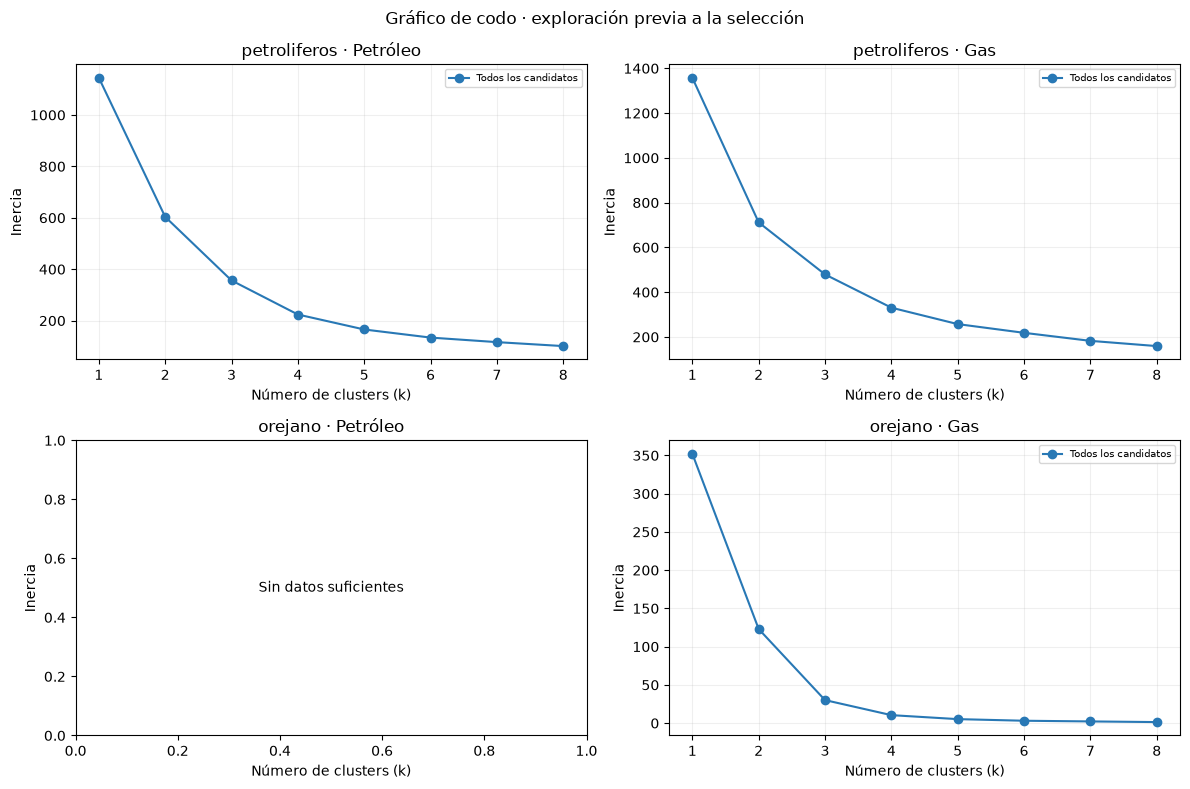

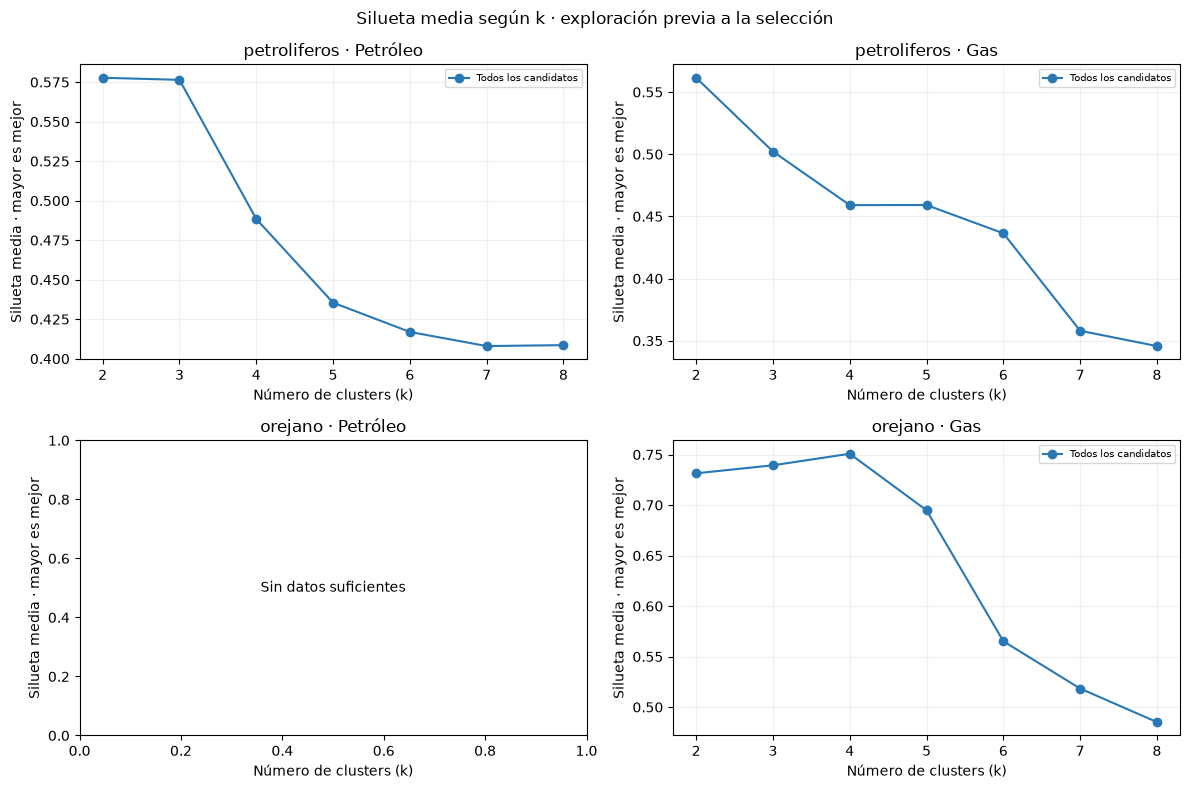

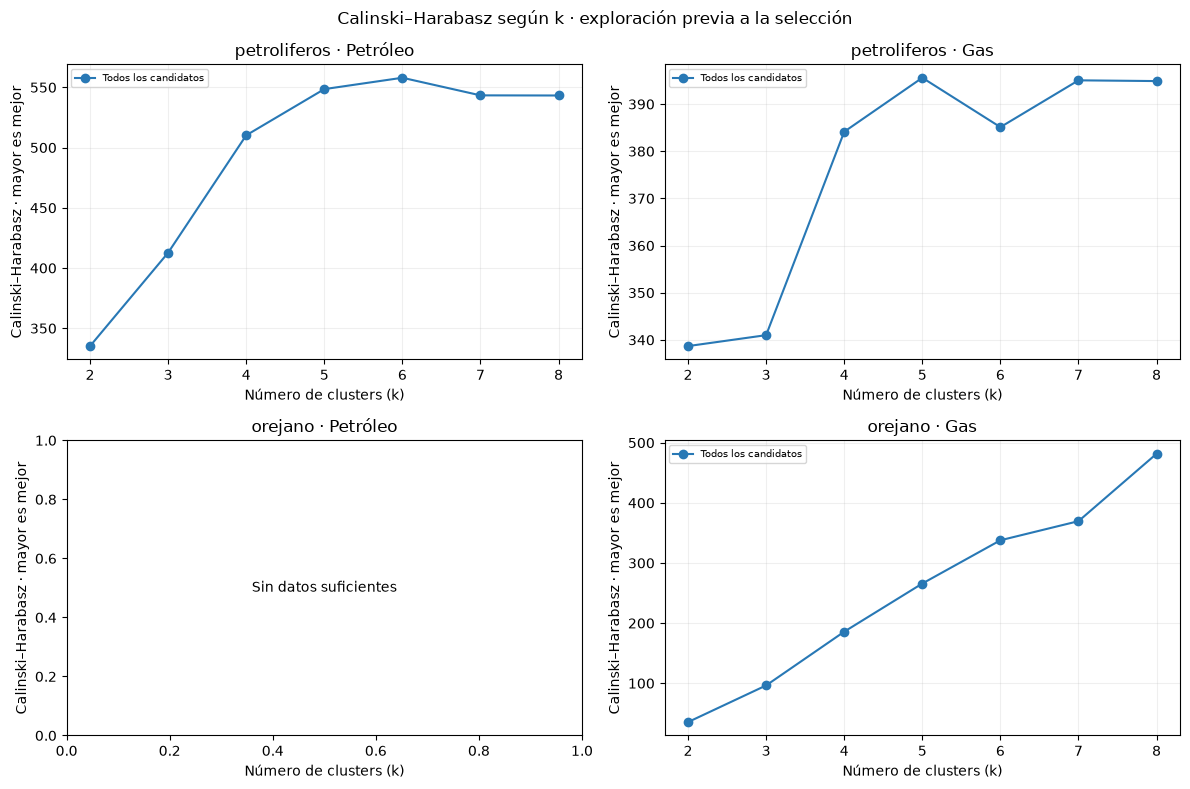

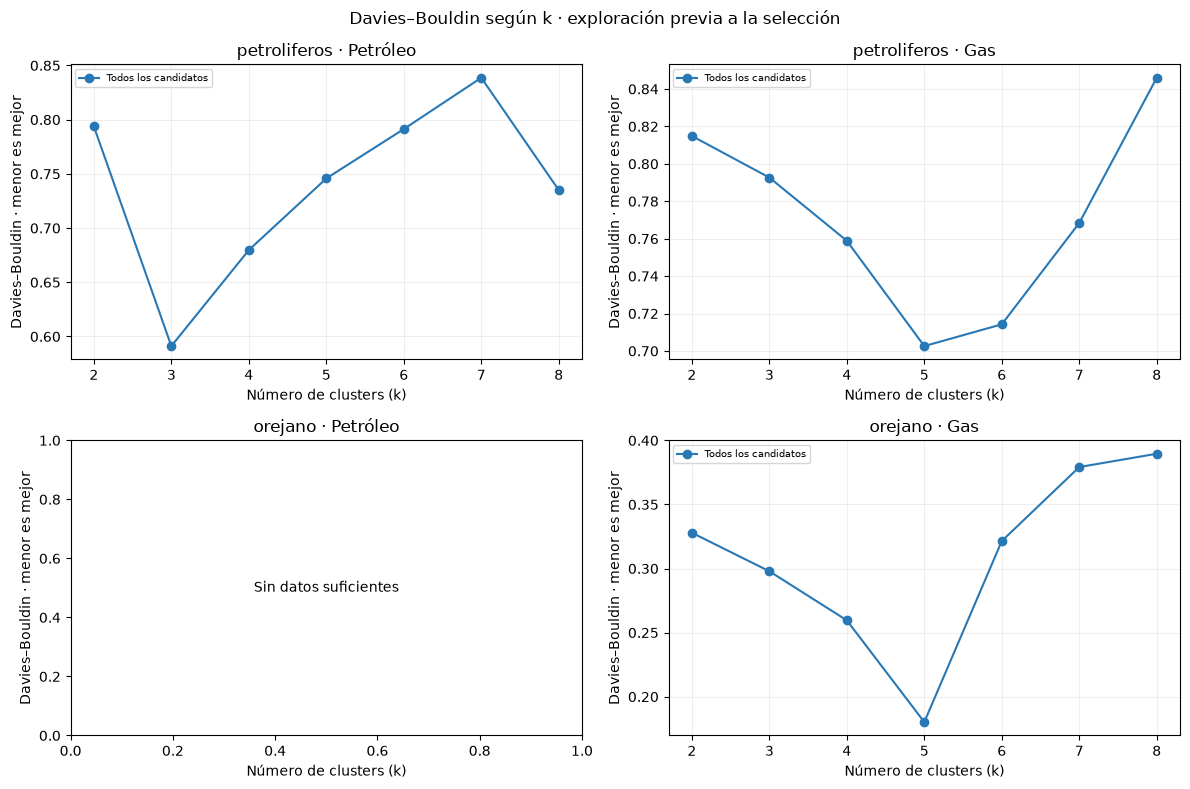

In [75]:
# Mostramos la exploración completa sin señalar una cantidad elegida de antemano.
metricas_graficos = [
    ('inercia', 'Gráfico de codo', 'Inercia'),
    ('silueta', 'Silueta media según k', 'Silueta media · mayor es mejor'),
    ('calinski_harabasz', 'Calinski–Harabasz según k', 'Calinski–Harabasz · mayor es mejor'),
    ('davies_bouldin', 'Davies–Bouldin según k', 'Davies–Bouldin · menor es mejor'),
]
for metrica, titulo, etiqueta_y in metricas_graficos:
    fig, axes = plt.subplots(len(POBLACIONES), len(TASAS), figsize=(12, 8), squeeze=False)
    for fila, poblacion in enumerate(POBLACIONES):
        for columna, tasa in enumerate(TASAS):
            ax = axes[fila, columna]
            g = comparacion_k.loc[comparacion_k.poblacion.eq(poblacion) & comparacion_k.tasa.eq(tasa)]
            puntos = g.dropna(subset=[metrica])
            ax.set(title=f'{poblacion} · {NOMBRES[tasa]}', xlabel='Número de clusters (k)', ylabel=etiqueta_y)
            if puntos.empty:
                ax.text(.5, .5, 'Sin datos suficientes', ha='center', va='center', transform=ax.transAxes)
                continue
            ax.plot(puntos.k, puntos[metrica], 'o-', color='#2878b5', label='Todos los candidatos')
            ax.set_xticks(puntos.k)
            ax.grid(alpha=.2)
            ax.legend(fontsize=7)
    fig.suptitle(f'{titulo} · exploración previa a la selección')
    plt.tight_layout()
    plt.show()

## 6.1. Resultado de la exploración y selección de k

Después de revisar los gráficos de codo, silueta, Calinski–Harabasz y Davies–Bouldin de la sección 6, adoptamos las siguientes cantidades de clusters para la ventana **octubre de 2025 a septiembre de 2026**:

| Población | Fluido | k elegido | Silueta media |
|---|---|---:|---:|
| La Amarga Chica + Loma Campana | Petróleo | **2** | **0,5778** |
| La Amarga Chica + Loma Campana | Gas | **2** | **0,5615** |
| El Orejano | Gas | **4** | **0,7508** |
| El Orejano | Petróleo | No se asigna | Sin curvas evaluables suficientes |

**La Amarga Chica + Loma Campana — petróleo: elegimos k=2.** La silueta es prácticamente igual con dos y tres clusters: 0,5778 y 0,5764, respectivamente. Con cuatro grupos baja a 0,4884. El codo muestra una transición gradual alrededor de tres o cuatro grupos; no señala un único valor de forma concluyente. Davies–Bouldin favorece k=3 y Calinski–Harabasz alcanza su máximo en k=6, por lo que no hay consenso entre criterios. Elegimos dos perfiles por simplicidad e interpretación, conservando la mayor silueta observada. Es una decisión exploratoria: k=3 sigue siendo una alternativa razonable si la revisión operativa justifica distinguir un tercer comportamiento.

**La Amarga Chica + Loma Campana — gas: elegimos k=2.** La mayor silueta corresponde a dos clusters (0,5615); disminuye a 0,5022 con tres y a aproximadamente 0,4591 con cuatro o cinco. La inercia continúa bajando y el cambio de pendiente del codo es gradual, alrededor de tres o cuatro grupos. Calinski–Harabasz y Davies–Bouldin favorecen k=5, pero esa partición tiene una silueta menor. Priorizamos la separación que muestra la silueta y una interpretación con dos perfiles; no presentamos esta elección como un acuerdo entre todas las métricas.

**El Orejano — gas: elegimos k=4.** La silueta aumenta de 0,7314 con dos grupos a 0,7394 con tres y alcanza su máximo en 0,7508 con cuatro. Luego cae a 0,6948 con cinco y continúa disminuyendo. En el codo, la reducción de inercia es marcada hasta tres o cuatro grupos y los descensos absolutos posteriores son menores. Davies–Bouldin favorece k=5 y Calinski–Harabasz sigue creciendo hasta k=8, el límite explorado. Elegimos cuatro como compromiso entre separación y complejidad. La mejora de silueta frente a k=3 es pequeña y la muestra contiene solo 21 pozos. 

**El Orejano — petróleo: no elegimos k.** En esta ventana no hay pozos con curvas de petróleo evaluables suficientes para realizar la exploración. No corresponde extrapolar la elección de gas ni imponer una partición.

Los clusters se nombran **Perfil 1/k, Perfil 2/k, …**, ordenados de menor a mayor desviación agregada respecto de la curva propia. 

## 6.2. Silueta de cada pozo para el k seleccionado

El promedio puede ocultar asignaciones poco claras. El siguiente gráfico ordena las siluetas
individuales dentro de cada categoría. Una silueta negativa señala que, según estas distancias,
el pozo está en promedio más cerca de otro cluster. La línea roja marca la media del modelo.
Se exportan el valor por pozo, la media por cluster y la proporción de valores negativos.
El ARI posterior a la selección complementa estas métricas al comprobar estabilidad entre semillas;
no es accuracy ni una comparación contra etiquetas verdaderas.

In [76]:
# ELECCIÓN MANUAL DESPUÉS DE REVISAR LOS GRÁFICOS DE LA SECCIÓN 6.
# No se ejecuta una regla automática para elegir k. Este diccionario registra la conclusión.
# Valores para la ventana octubre de 2025–septiembre de 2026: revisar si cambian fuente o corte.
# Para modificar una decisión, editar aquí el k y su justificación y ejecutar desde esta celda.
K_ELEGIDO = {
    ('petroliferos', 'prod_pet_dia'): 2,
    ('petroliferos', 'prod_gas_dia'): 2,
    ('orejano', 'prod_pet_dia'): None,  # Sin curvas evaluables de petróleo en esta ventana.
    ('orejano', 'prod_gas_dia'): 4,
}
JUSTIFICACION_K = {
    ('petroliferos', 'prod_pet_dia'): 'Siluetas de k=2 y k=3 similares; se eligen dos perfiles por simplicidad. El codo sugiere revisar k=3.',
    ('petroliferos', 'prod_gas_dia'): 'k=2 tiene la mayor silueta. El codo y otros índices discrepan; se prioriza separación e interpretación.',
    ('orejano', 'prod_pet_dia'): 'Sin producción positiva suficiente para ajustar curvas y explorar k.',
    ('orejano', 'prod_gas_dia'): 'k=4 presenta la mayor silueta. El codo sugiere k=3; Calinski y Davies favorecen otras particiones.',
}

# Validamos que el k escrito fue explorado y mostramos su métrica y el motivo de la decisión.
# La comprobación evita errores de edición; no filtra por tamaños ni ocupación de clusters.
filas_seleccion = []
for poblacion in POBLACIONES:
    for tasa in TASAS:
        clave = (poblacion, tasa)
        if clave not in K_ELEGIDO:
            raise ValueError(f'Falta registrar la elección manual para {clave}.')
        elegido = K_ELEGIDO[clave]
        fila = dict(poblacion=poblacion, tasa=tasa, fluido=NOMBRES[tasa],
            k_seleccionado=elegido, motivo=JUSTIFICACION_K.get(clave, 'Sin justificación registrada'),
            metodo_seleccion='Manual, después de revisar gráficos')
        if clave not in espacios:
            if elegido is not None:
                raise ValueError(f'{clave}: no hay exploración disponible; usar None.')
            fila['estado'] = 'Sin datos suficientes para explorar k'
        elif elegido is None:
            fila['estado'] = 'Pendiente de elección manual'
        else:
            if isinstance(elegido, bool) or not isinstance(elegido, (int, np.integer)):
                raise ValueError(f'{clave}: el k manual debe ser entero o None.')
            if elegido < 2 or (poblacion, tasa, elegido) not in candidatos:
                raise ValueError(f'{clave}: elegir un k >= 2 presente en la tabla explorada.')
            metrica = comparacion_k.loc[comparacion_k.poblacion.eq(poblacion)
                & comparacion_k.tasa.eq(tasa) & comparacion_k.k.eq(elegido)].iloc[0]
            fila.update(estado='Seleccionado', silueta_seleccionada=float(metrica.silueta))
        filas_seleccion.append(fila)
resumen_seleccion_k = pd.DataFrame(filas_seleccion)
resumen_seleccion_k['k_seleccionado'] = pd.array(resumen_seleccion_k.k_seleccionado, dtype='Int64')
display(resumen_seleccion_k)

# Solo ahora asignamos perfiles usando el ajuste candidato seleccionado para cada caso.
perfiles['categoria'] = pd.Series(pd.NA, index=perfiles.index, dtype='string')
perfiles['cluster_id'] = pd.Series(pd.NA, index=perfiles.index, dtype='Int64')
perfiles['orden_perfil'] = pd.Series(pd.NA, index=perfiles.index, dtype='Int64')
perfiles['k_seleccionado'] = pd.Series(pd.NA, index=perfiles.index, dtype='Int64')
perfiles['distancia_centro'] = np.nan
perfiles['requiere_revision_centroides'] = pd.Series(pd.NA, index=perfiles.index, dtype='boolean')
modelos, filas_centros, filas_diagnosticos = {}, [], list(estados_exploracion)
for seleccion in resumen_seleccion_k.itertuples(index=False):
    poblacion, tasa = seleccion.poblacion, seleccion.tasa
    if seleccion.estado != 'Seleccionado':
        if (poblacion, tasa) in espacios:
            filas_diagnosticos.append(dict(poblacion=poblacion, fluido=NOMBRES[tasa],
                pozos=len(espacios[(poblacion, tasa)]['indices']), estado=seleccion.estado))
        continue
    espacio = espacios[(poblacion, tasa)]
    idx, z, escalador = espacio['indices'], espacio['z'], espacio['escalador']
    k_elegido = int(seleccion.k_seleccionado)
    km = candidatos[(poblacion, tasa, k_elegido)]
    orden = np.argsort(km.cluster_centers_.mean(axis=1), kind='stable')
    categorias = [f'Perfil {pos+1}/{k_elegido}' + (' · menor desviación' if pos == 0 else
        ' · mayor desviación' if pos == k_elegido-1 else '') for pos in range(k_elegido)]
    etiquetas = {int(cluster): categorias[pos] for pos, cluster in enumerate(orden)}
    orden_por_cluster = {int(cluster): pos+1 for pos, cluster in enumerate(orden)}
    colores = {categoria: plt.get_cmap('RdYlBu_r')(valor) for categoria, valor in zip(categorias, np.linspace(.15, .85, k_elegido))}
    orden_coherente = bool((np.diff(km.cluster_centers_[orden], axis=0) >= -1e-9).all())
    perfiles.loc[idx, 'categoria'] = [etiquetas[int(c)] for c in km.labels_]
    perfiles.loc[idx, 'orden_perfil'] = [orden_por_cluster[int(c)] for c in km.labels_]
    perfiles.loc[idx, 'cluster_id'] = km.labels_
    perfiles.loc[idx, 'k_seleccionado'] = k_elegido
    perfiles.loc[idx, 'distancia_centro'] = np.linalg.norm(z - km.cluster_centers_[km.labels_], axis=1)
    perfiles.loc[idx, 'requiere_revision_centroides'] = not orden_coherente
    centros_originales = pd.DataFrame(escalador.inverse_transform(km.cluster_centers_), columns=FEATURES)
    centros_originales[MAGNITUDES] = np.expm1(centros_originales[MAGNITUDES])
    for cluster in orden:
        filas_centros.append(dict(poblacion=poblacion, fluido=NOMBRES[tasa], k_seleccionado=k_elegido,
            cluster_id=int(cluster), orden_perfil=orden_por_cluster[int(cluster)], categoria=etiquetas[int(cluster)],
            pozos=int(np.sum(km.labels_ == cluster)), indice_orden=float(km.cluster_centers_[cluster].mean()),
            requiere_revision=not orden_coherente, **centros_originales.loc[cluster].to_dict()))
    aris = [adjusted_rand_score(km.labels_, KMeans(n_clusters=k_elegido, n_init=N_INIT,
        random_state=s).fit_predict(z)) for s in [7, 21, 84]]
    fila_metrica = comparacion_k.loc[comparacion_k.poblacion.eq(poblacion) & comparacion_k.tasa.eq(tasa) & comparacion_k.k.eq(k_elegido)].iloc[0]
    filas_diagnosticos.append(dict(poblacion=poblacion, fluido=NOMBRES[tasa], pozos=len(z), estado='Ajustado',
        k_seleccionado=k_elegido, silueta=fila_metrica.silueta, calinski_harabasz=fila_metrica.calinski_harabasz,
        davies_bouldin=fila_metrica.davies_bouldin, ARI_minimo=min(aris), inercia=km.inertia_,
        menor_grupo=int(np.bincount(km.labels_).min()), requiere_revision=not orden_coherente))
    modelos[(poblacion, tasa)] = dict(escalador=escalador, kmeans=km, k_seleccionado=k_elegido,
        etiquetas=etiquetas, categorias=categorias, colores=colores)
centroides = pd.DataFrame(filas_centros)
diagnosticos = pd.DataFrame(filas_diagnosticos)
display(centroides.round(4))
display(diagnosticos.round(4))
if not modelos:
    raise ValueError('Ningún candidato respalda una asignación de perfiles; revisar la exploración.')

,poblacion,tasa,fluido,k_seleccionado,motivo,metodo_seleccion,estado,silueta_seleccionada
0,petroliferos,prod_pet_dia,Petróleo,2,Siluetas de k=2 y k=3 similares; se eligen dos...,"Manual, después de revisar gráficos",Seleccionado,0.577772
1,petroliferos,prod_gas_dia,Gas,2,k=2 tiene la mayor silueta. El codo y otros ín...,"Manual, después de revisar gráficos",Seleccionado,0.561514
2,orejano,prod_pet_dia,Petróleo,<NA>,Sin producción positiva suficiente para ajusta...,"Manual, después de revisar gráficos",Sin datos suficientes para explorar k,NaN
3,orejano,prod_gas_dia,Gas,4,k=4 presenta la mayor silueta. El codo sugiere...,"Manual, después de revisar gráficos",Seleccionado,0.750795


,poblacion,fluido,k_seleccionado,cluster_id,orden_perfil,categoria,pozos,indice_orden,requiere_revision,desvio_absoluto_mediano,desvio_absoluto_p90,fraccion_desvios,racha_desvios_fraccion
0,petroliferos,Petróleo,2,0,1,Perfil 1/2 · menor desviación,286,-0.0807,False,0.1012,0.2974,0.1235,0.0868
1,petroliferos,Petróleo,2,1,2,Perfil 2/2 · mayor desviación,90,1.2948,False,0.3705,1.2065,0.5574,0.3852
2,petroliferos,Gas,2,0,1,Perfil 1/2 · menor desviación,297,-0.1643,False,0.1357,0.3902,0.1871,0.1221
3,petroliferos,Gas,2,1,2,Perfil 2/2 · mayor desviación,78,1.4280,False,0.3941,1.1990,0.6047,0.4530
4,orejano,Gas,4,0,1,Perfil 1/4 · menor desviación,5,-1.5171,True,0.0879,0.2650,0.1000,0.0667
5,orejano,Gas,4,1,2,Perfil 2/4,11,0.0255,True,0.2929,0.9022,0.4394,0.3788
6,orejano,Gas,4,3,3,Perfil 3/4,3,1.3604,True,0.7658,1.3512,0.9444,0.9444
7,orejano,Gas,4,2,4,Perfil 4/4 · mayor desviación,2,3.2758,True,0.7117,4.0708,0.8750,0.8333


,poblacion,tasa,fluido,pozos,estado,k_seleccionado,silueta,calinski_harabasz,davies_bouldin,ARI_minimo,inercia,menor_grupo,requiere_revision
0,orejano,prod_pet_dia,Petróleo,0,Sin al menos tres pozos para evaluar separación,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,petroliferos,NaN,Petróleo,376,Ajustado,2.0,0.5778,335.2104,0.7938,0.9656,603.6947,90.0,False
2,petroliferos,NaN,Gas,375,Ajustado,2.0,0.5615,338.6868,0.8149,1.0000,711.6893,78.0,False
3,orejano,NaN,Gas,21,Ajustado,4.0,0.7508,185.7343,0.2596,1.0000,10.4271,2.0,True


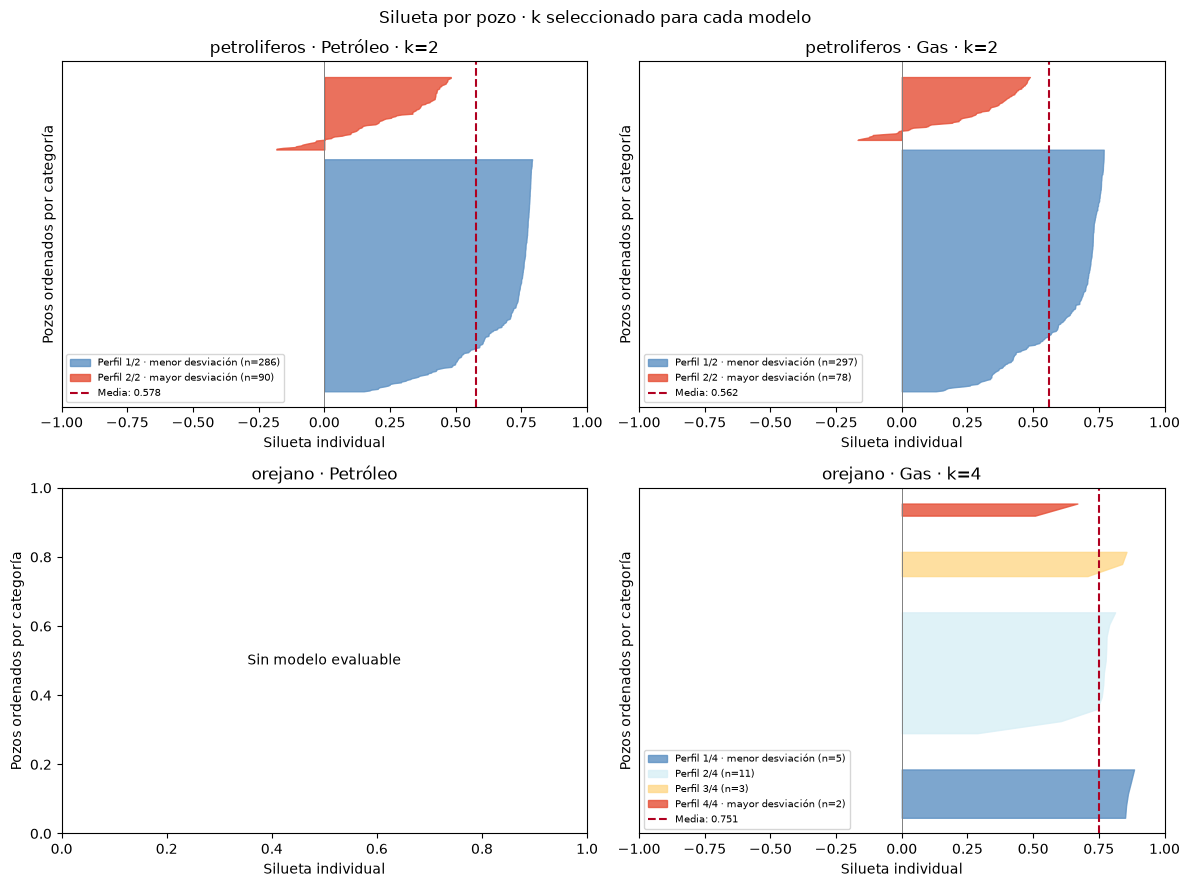

,poblacion,fluido,k_seleccionado,categoria,pozos,silueta_media,silueta_minima,fraccion_negativa
0,petroliferos,Petróleo,2,Perfil 1/2 · menor desviación,286,0.6802,0.1494,0.0000
1,petroliferos,Petróleo,2,Perfil 2/2 · mayor desviación,90,0.2521,-0.1831,0.1333
2,petroliferos,Gas,2,Perfil 1/2 · menor desviación,297,0.6384,0.1291,0.0000
3,petroliferos,Gas,2,Perfil 2/2 · mayor desviación,78,0.2686,-0.1684,0.1538
4,orejano,Gas,4,Perfil 1/4 · menor desviación,5,0.8643,0.8501,0.0000
5,orejano,Gas,4,Perfil 2/4,11,0.7153,0.2875,0.0000
6,orejano,Gas,4,Perfil 3/4,3,0.8003,0.7071,0.0000
7,orejano,Gas,4,Perfil 4/4 · mayor desviación,2,0.5878,0.5072,0.0000


In [77]:
# Calculamos las siluetas individuales del k seleccionado y las guardamos en los perfiles.
perfiles['silueta_individual'] = np.nan
filas_silueta = []
fig, axes = plt.subplots(len(POBLACIONES), len(TASAS), figsize=(12, 9), squeeze=False)
for fila, poblacion in enumerate(POBLACIONES):
    for columna, tasa in enumerate(TASAS):
        ax = axes[fila, columna]
        ax.set(title=f'{poblacion} · {NOMBRES[tasa]}', xlabel='Silueta individual', ylabel='Pozos ordenados por categoría')
        paquete = modelos.get((poblacion, tasa))
        if paquete is None:
            ax.text(.5, .5, 'Sin modelo evaluable', ha='center', va='center', transform=ax.transAxes)
            continue
        idx = perfiles.index[perfiles.poblacion.eq(poblacion) & perfiles.tasa.eq(tasa) & perfiles.categoria.notna()]
        x = perfiles.loc[idx, FEATURES].copy()
        x[MAGNITUDES] = np.log1p(x[MAGNITUDES])
        z = paquete['escalador'].transform(x)
        etiquetas = paquete['kmeans'].labels_
        ax.set_title(f"{poblacion} · {NOMBRES[tasa]} · k={paquete['k_seleccionado']}")
        if not 2 <= len(np.unique(etiquetas)) < len(z):
            ax.text(.5, .5, 'Silueta no definida para esta muestra', ha='center', va='center', transform=ax.transAxes)
            continue
        siluetas = silhouette_samples(z, etiquetas)
        perfiles.loc[idx, 'silueta_individual'] = siluetas
        # Dibujamos cada grupo separado por un margen para distinguir tamaños y dispersión.
        inicio_y = 0
        for categoria in paquete['categorias']:
            mascara = perfiles.loc[idx, 'categoria'].eq(categoria).to_numpy(dtype=bool)
            valores = np.sort(siluetas[mascara])
            if not len(valores):
                continue
            y = np.arange(inicio_y, inicio_y + len(valores))
            ax.fill_betweenx(y, 0, valores, color=paquete['colores'][categoria], alpha=.8, label=f'{categoria} (n={len(valores)})')
            filas_silueta.append(dict(poblacion=poblacion, fluido=NOMBRES[tasa], k_seleccionado=paquete['k_seleccionado'], categoria=categoria,
                pozos=len(valores), silueta_media=float(valores.mean()),
                silueta_minima=float(valores.min()), fraccion_negativa=float(np.mean(valores < 0))))
            inicio_y += len(valores) + max(2, int(len(z) * .03))
        ax.axvline(float(siluetas.mean()), color='#b00020', linestyle='--', label=f'Media: {siluetas.mean():.3f}')
        ax.axvline(0, color='gray', linewidth=.7)
        ax.set_xlim(-1, 1)
        ax.set_yticks([])
        ax.legend(fontsize=7, loc='lower left')
fig.suptitle('Silueta por pozo · k seleccionado para cada modelo')
plt.tight_layout()
plt.show()
silueta_por_cluster = pd.DataFrame(filas_silueta)
display(silueta_por_cluster.round(4))

## 7. Tamaños de grupo y lectura de centroides

Los gráficos muestran cuántos pozos reciben cada categoría. No se fuerzan tamaños iguales.
Los centroides exportados son los centros inversamente transformados: debido a `log1p`, las
magnitudes no equivalen al promedio aritmético original. Las frecuencias conservan su escala 0–1.
Revisar los avisos de perfiles cruzados, grupos pequeños y curvas en los límites antes de usar etiquetas.

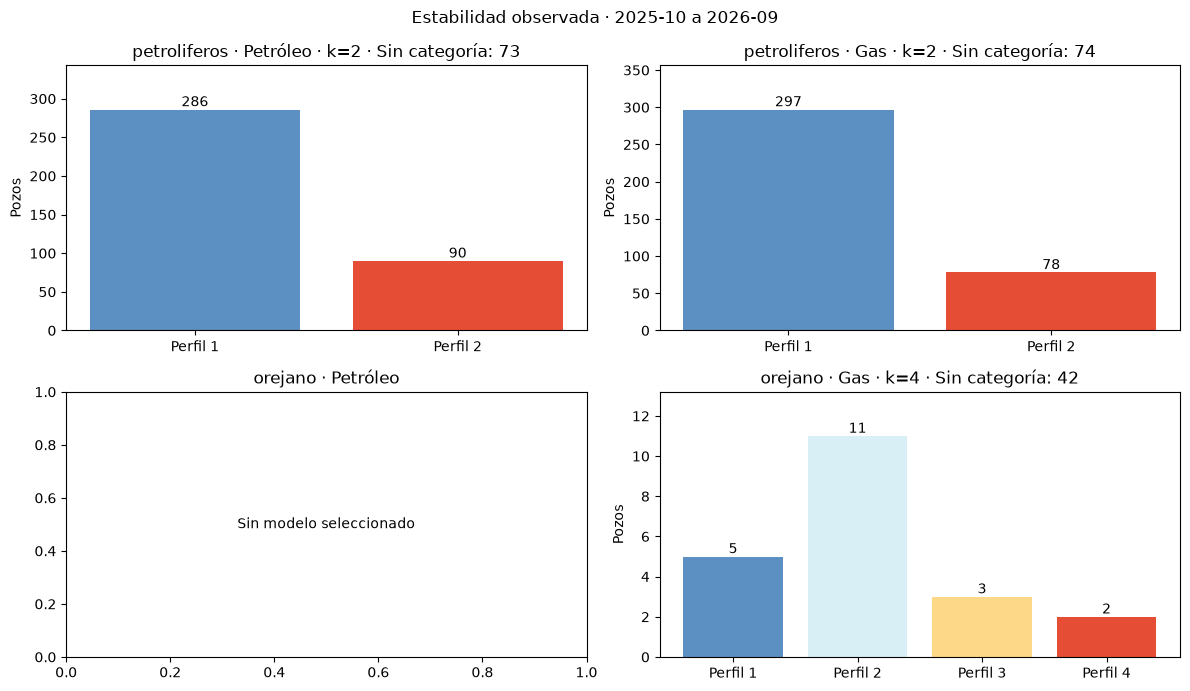

fluido,idpozo,poblacion,Gas,Petróleo
0,145735,petroliferos,<NA>,<NA>
1,145739,petroliferos,Perfil 1/2 · menor desviación,Perfil 1/2 · menor desviación
2,145881,petroliferos,Perfil 1/2 · menor desviación,Perfil 1/2 · menor desviación
3,145882,petroliferos,<NA>,<NA>
4,145883,petroliferos,<NA>,<NA>
5,145884,petroliferos,<NA>,<NA>
6,145887,petroliferos,Perfil 1/2 · menor desviación,Perfil 2/2 · mayor desviación
7,145888,petroliferos,Perfil 1/2 · menor desviación,Perfil 1/2 · menor desviación
8,145889,petroliferos,<NA>,<NA>
9,145890,petroliferos,<NA>,<NA>


In [78]:
# Comparamos distribuciones sin mezclar los cuatro modelos previstos ni sus escalas.
fig, axes = plt.subplots(len(POBLACIONES), len(TASAS), figsize=(12, 7), squeeze=False)
for fila, poblacion in enumerate(POBLACIONES):
    for columna, tasa in enumerate(TASAS):
        ax = axes[fila, columna]
        sub = perfiles.loc[perfiles.poblacion.eq(poblacion) & perfiles.tasa.eq(tasa)]
        paquete = modelos.get((poblacion, tasa))
        if paquete is None:
            ax.text(.5, .5, 'Sin modelo seleccionado', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f'{poblacion} · {NOMBRES[tasa]}')
            continue
        categorias = paquete['categorias']
        posiciones = np.arange(len(categorias))
        conteo = sub.categoria.value_counts().reindex(categorias, fill_value=0)
        ax.bar(posiciones, conteo.to_numpy(), color=[paquete['colores'][c] for c in categorias])
        ax.set_xticks(posiciones, [f'Perfil {i+1}' for i in posiciones])
        for pos, cantidad in enumerate(conteo):
            ax.text(pos, cantidad, str(cantidad), ha='center', va='bottom')
        sin_categoria = int(sub.categoria.isna().sum())
        ax.set(title=f'{poblacion} · {NOMBRES[tasa]} · k={paquete['k_seleccionado']} · Sin categoría: {sin_categoria}', ylabel='Pozos')
        ax.margins(y=.2)
fig.suptitle(f'Estabilidad observada · {inicio:%Y-%m} a {corte:%Y-%m}')
plt.tight_layout()
plt.show()

# Dejamos una tabla breve para consultar las categorías de petróleo y gas de cada pozo.
resumen_pozos = perfiles.pivot(index=['idpozo', 'poblacion'], columns='fluido', values='categoria').reset_index()
display(resumen_pozos.head(20))

## 8. Inspección de curvas, picos y contexto operativo

La función `graficar_pozo(idpozo)` muestra petróleo y gas con su curva, eventos y cambios operativos.
Las bandas representan el umbral normalizado configurado; no son intervalos de confianza.
Los eventos se colorean por coincidencia con contexto disponible. Un evento sin coincidencia es **sin contexto registrado aquí**, no necesariamente inexplicable en campo.


In [79]:
def graficar_pozo(idpozo):
    """Muestra tasas, curva propia, residuos y contexto de un pozo evaluado."""
    filas = perfiles.loc[perfiles.idpozo.eq(idpozo)]
    if filas.empty:
        raise ValueError('El pozo no pertenece al universo analizado.')
    # Desactivamos el registro interactivo al crear esta figura para evitar emisiones automáticas.
    with plt.ioff():
        fig, axes = plt.subplots(len(TASAS), 2, figsize=(15, 7), squeeze=False)
    for fila, tasa in enumerate(TASAS):
        ax, ax_residuo = axes[fila]
        ficha = filas.loc[filas.tasa.eq(tasa)].iloc[0]
        g = detalle.loc[detalle.idpozo.eq(idpozo) & detalle.fluido.eq(NOMBRES[tasa])].sort_values('fecha')
        if g.empty:
            ax.text(.05, .5, ficha.estado, transform=ax.transAxes, wrap=True)
            ax.set_title(NOMBRES[tasa])
            ax_residuo.set_visible(False)
            continue
        # El umbral se transforma a unidades de producción para dibujar una banda interpretable.
        amplitud = UMBRAL_DESVIO * (g.curva + g.piso)
        ax.fill_between(g.fecha, np.maximum(0, g.curva - amplitud), g.curva + amplitud,
                        color='gray', alpha=.15, label='Banda de referencia')
        ax.plot(g.fecha, g.observado, 'o-', label='Observado', color='#2878b5')
        ax.plot(g.fecha, g.curva, '--', label='Declinación propia', color='black')
        for con_contexto, color, etiqueta in [(False, '#d62728', 'Desvío sin contexto registrado'), (True, '#e58b00', 'Desvío con contexto operativo')]:
            puntos = g.loc[g.desvio_grande & g.evento_con_contexto.eq(con_contexto)]
            ax.scatter(puntos.fecha, puntos.observado, color=color, s=65, zorder=5, label=etiqueta)
        for fecha in g.loc[g.cambio_extraccion, 'fecha']:
            ax.axvline(fecha, color='#8a4baf', linestyle=':', alpha=.6)
        categoria = ficha.categoria if pd.notna(ficha.categoria) else 'Sin categoría'
        ax.set(title=f'{NOMBRES[tasa]} · {categoria}', ylabel=UNIDADES[tasa])
        ax.legend(fontsize=7)
        # Los residuos permiten comparar separación respecto de la curva sin mezclar unidades.
        ax_residuo.axhline(0, color='black', linewidth=.8)
        for limite in [-UMBRAL_DESVIO, UMBRAL_DESVIO]:
            ax_residuo.axhline(limite, color='gray', linestyle='--')
        ax_residuo.plot(g.fecha, g.residuo_normalizado, 'o-', color='#8a4baf')
        ax_residuo.set(title='Desviación normalizada', ylabel='(observado − curva) / (curva + piso)')
        for eje in [ax, ax_residuo]:
            eje.grid(alpha=.2)
            eje.tick_params(axis='x', rotation=30)
    edad_inicio, edad_fin = filas.edad_inicio.iloc[0], filas.edad_fin.iloc[0]
    fig.suptitle(f'Pozo {idpozo} · Edad observada {edad_inicio:g}–{edad_fin:g} meses · Ventana {inicio:%Y-%m} a {corte:%Y-%m}')
    fig.tight_layout()
    # Cerramos solo esta figura y la devolvemos: no usamos show(), que muestra todas las abiertas.
    plt.close(fig)
    return fig

# Usamos una única imagen del widget: cambiar sus bytes reemplaza el gráfico, sin añadir salidas.
import io
import ipywidgets as widgets

# Desconectamos controles anteriores si se reejecuta la celda para no acumular callbacks.
if 'selector_pozo' in globals():
    selector_pozo.unobserve_all()
for nombre_control in ['selector_pozo', 'salida_pozo', 'imagen_pozo', 'contenedor_pozo']:
    control_anterior = globals().get(nombre_control)
    if control_anterior is not None:
        control_anterior.close()

# Mostramos todos los pozos del universo; cada opción incluye el área para facilitar la búsqueda.
opciones_pozos = perfiles[['idpozo', 'areayacimiento']].drop_duplicates('idpozo').sort_values('idpozo')
ID_POZO_EJEMPLO = perfiles.loc[perfiles.estado.eq('Evaluable')].sort_values('desvio_absoluto_p90', ascending=False).idpozo.iloc[0]
selector_pozo = widgets.Dropdown(
    options=[(f'{r.idpozo} · {r.areayacimiento}', r.idpozo) for r in opciones_pozos.itertuples(index=False)],
    value=ID_POZO_EJEMPLO,
    description='Pozo:',
    layout=widgets.Layout(width='600px', max_width='100%'),
    style={'description_width': 'initial'},
)
imagen_pozo = widgets.Image(format='png', layout=widgets.Layout(width='100%'))


def actualizar_pozo(cambio=None):
    """Reemplaza la imagen existente al seleccionar otro pozo; no crea salidas adicionales."""
    figura = graficar_pozo(selector_pozo.value)
    try:
        with io.BytesIO() as buffer:
            figura.savefig(buffer, format='png', dpi=110, bbox_inches='tight')
            imagen_pozo.value = buffer.getvalue()
    finally:
        # Liberamos la figura incluso si falla la conversión a imagen.
        plt.close(figura)


# Solo hay un observador y un contenedor visible con una única imagen actualizable.
selector_pozo.observe(actualizar_pozo, names='value')
contenedor_pozo = widgets.VBox([selector_pozo, imagen_pozo])
actualizar_pozo()
display(contenedor_pozo)
